In [1]:
# Level 3 - Task 1: Feature Engineering and Model Comparison

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import os
import pandas as pd

folder = r"C:\Users\basav\OneDrive\Documents\SAN_Data_Science_Internship\Level 3\Task_1_Feature_Engineering_Model_Comparison"

print("Files in your Task 1 folder:")
for file in os.listdir(folder):
    print(file)

Files in your Task 1 folder:
.ipynb_checkpoints
charts
cleaned_student_performance.csv
Level_3_Task_1_Feature_Engineering_Model_Comparison.ipynb
model_comparison_results.csv
model_comparison_results_updated.csv
README.md


In [3]:
data_path = os.path.join(folder, "cleaned_student_performance.csv")

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.head()

Dataset loaded successfully!
Dataset shape: (2392, 15)

Column names:
['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4


In [4]:
# Create meaningful features for model improvement

df["StudyTimePerAbsence"] = df["StudyTimeWeekly"] / (df["Absences"] + 1)

df["TotalSupport"] = (
    df["Tutoring"] +
    df["ParentalSupport"]
)

df["ExtracurricularCount"] = (
    df["Extracurricular"] +
    df["Sports"] +
    df["Music"] +
    df["Volunteering"]
)

print("Feature engineering completed!")
print("New features:")
print(["StudyTimePerAbsence", "TotalSupport", "ExtracurricularCount"])

df.head()

Feature engineering completed!
New features:
['StudyTimePerAbsence', 'TotalSupport', 'ExtracurricularCount']


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass,StudyTimePerAbsence,TotalSupport,ExtracurricularCount
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2,2.479215,3,1
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1,15.408756,1,0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4,0.155947,2,0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3,0.668589,3,1
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4,0.259583,4,0


In [5]:
# Separate input features and target variable

target = "GPA"

X = df.drop(columns=[target, "GradeClass", "StudentID"], errors="ignore")
y = df[target]

# Convert categorical columns into numeric columns
X = pd.get_dummies(X, drop_first=True)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Data preparation completed!")
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Input features:", X_train.shape[1])

Data preparation completed!
Training samples: 1913
Testing samples: 479
Input features: 15


In [6]:
# Train two machine learning models

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)

print("Model training completed!")
display(results_df.round(4))

Model training completed!


,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.1554,0.1968,0.9531
1,Random Forest,0.1810,0.2322,0.9348


In [7]:
results_path = os.path.join(
    folder, "model_comparison_results_updated.csv"
)

results_df.to_csv(results_path, index=False)

print("Results saved successfully!")
print("Saved to:", results_path)

display(results_df.round(4))

Results saved successfully!
Saved to: C:\Users\basav\OneDrive\Documents\SAN_Data_Science_Internship\Level 3\Task_1_Feature_Engineering_Model_Comparison\model_comparison_results_updated.csv


,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.1554,0.1968,0.9531
1,Random Forest,0.1810,0.2322,0.9348


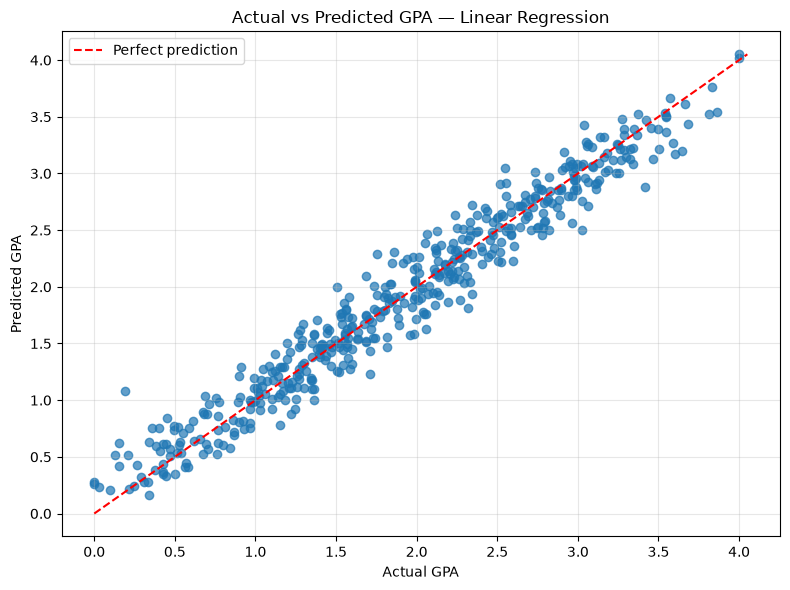

In [8]:
# Actual vs Predicted GPA — Linear Regression

best_model = models["Linear Regression"]
predictions = best_model.predict(X_test)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, predictions, alpha=0.7)

# Perfect prediction reference line
min_value = min(y_test.min(), predictions.min())
max_value = max(y_test.max(), predictions.max())
plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual GPA")
plt.ylabel("Predicted GPA")
plt.title("Actual vs Predicted GPA — Linear Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


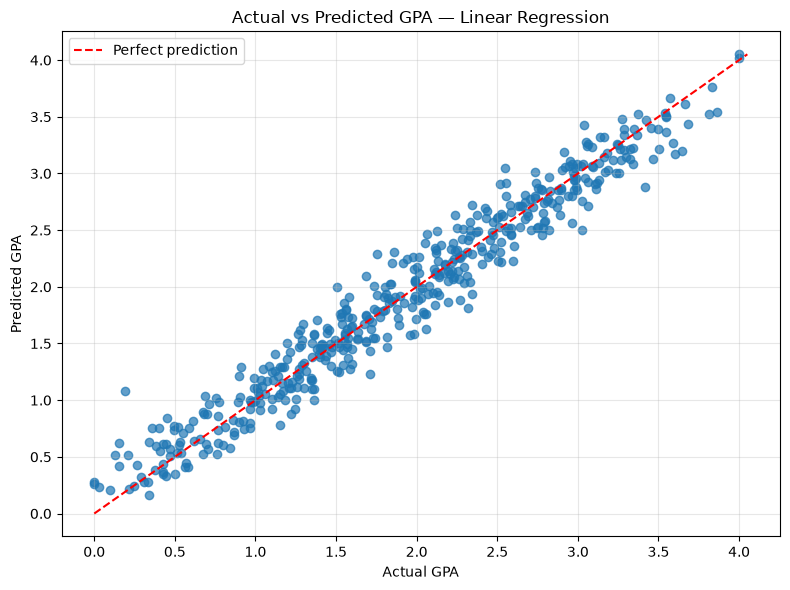

Chart saved to: C:\Users\basav\OneDrive\Documents\SAN_Data_Science_Internship\Level 3\Task_1_Feature_Engineering_Model_Comparison\charts\actual_vs_predicted_gpa.png


In [9]:
# Save the actual vs predicted GPA chart

chart_path = os.path.join(
    folder, "charts", "actual_vs_predicted_gpa.png"
)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, predictions, alpha=0.7)

min_value = min(y_test.min(), predictions.min())
max_value = max(y_test.max(), predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual GPA")
plt.ylabel("Predicted GPA")
plt.title("Actual vs Predicted GPA — Linear Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path)

OSError: [Errno 22] Invalid argument: 'C:\\Users\\basav\\OneDrive\\Documents\\SAN_Data_Science_Internship\\Level 3\\Task_1_Feature_Engineering_Model_Comparison\\charts\\model_comparison_mae.png'

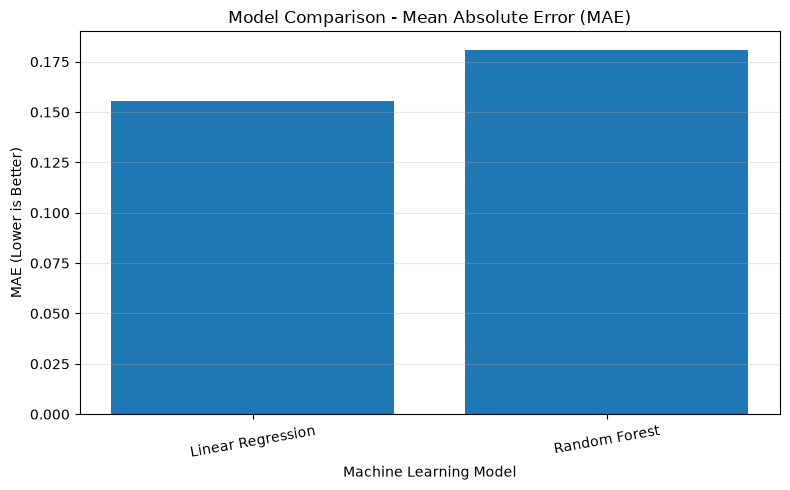

In [10]:
import os
import matplotlib.pyplot as plt

chart_folder = os.path.join(os.getcwd(), "charts")
os.makedirs(chart_folder, exist_ok=True)

chart_path = os.path.join(chart_folder, "model_comparison_mae.png")

plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["MAE"])
plt.title("Model Comparison - Mean Absolute Error (MAE)")
plt.xlabel("Machine Learning Model")
plt.ylabel("MAE (Lower is Better)")
plt.xticks(rotation=10)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved chart to:", chart_path)

In [ ]:
import pandas as pd
import os

folder = os.getcwd()

results_df = pd.read_csv(
    os.path.join(folder, "model_comparison_results_updated.csv")
)

display(results_df[["Model", "MAE"]])

In [ ]:
df = pd.read_csv("cleaned_student_performance.csv")

df["StudyTimePerAbsence"] = df["StudyTimeWeekly"] / (df["Absences"] + 1)
df["TotalSupport"] = df["Tutoring"] + df["ParentalSupport"]
df["ExtracurricularCount"] = (
    df["Extracurricular"] + df["Sports"] +
    df["Music"] + df["Volunteering"]
)

X = df.drop(columns=["GPA", "GradeClass", "StudentID"], errors="ignore")
y = df["GPA"]
X = pd.get_dummies(X, drop_first=True)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training and test data are ready.")

In [ ]:
baseline_prediction = np.full(len(y_test), y_train.mean())

baseline_result = {
    "Model": "Baseline",
    "MAE": mean_absolute_error(y_test, baseline_prediction),
    "RMSE": np.sqrt(mean_squared_error(y_test, baseline_prediction)),
    "R2 Score": r2_score(y_test, baseline_prediction)
}

results_df = pd.concat(
    [pd.DataFrame([baseline_result]), results_df],
    ignore_index=True
)

display(results_df.round(4))

In [ ]:
results_path = os.path.join(
    folder, "model_comparison_results_updated.csv"
)

results_df.to_csv(results_path, index=False)

print("All 3 model results saved successfully!")